<a href="https://colab.research.google.com/github/yuhui-0611/Unstructured-Data-Analysis/blob/main/UDA_Prompt_Engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q google-genai scikit-learn seaborn

import re, time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report)
from google import genai

SLEEP = 4       # seconds between API calls (free-tier rate limit)
LABELS = ['positive', 'neutral', 'negative']

In [ ]:
client = genai.Client(api_key="0000")
MODEL = "gemini-3.5-flash-lite"

def call_gemini(prompt):
    try:
        response = client.models.generate_content(
            model=MODEL, contents=prompt)
        return response.text
    except Exception as e:
        return f"ERROR: {e}"

In [ ]:
prompt = """
역할:
당신은 복잡한 개념을 초보자도 이해하기 쉽고 흥미롭게 설명하는 데이터 과학 선생님입니다.

과제:
감성 분석(Sentiment Analysis)이 무엇인지 설명하고, 실제 생활에서 어떻게 활용되는지 설명하세요.

요구사항:
- 감성 분석의 개념을 쉬운 언어로 설명하세요.
- 실제 생활에서 활용되는 사례를 정확히 2개 제시하세요.
- 각 사례에서 감성 분석이 어떻게 활용되는지 설명하세요.
- 대학생이 쉽게 이해할 수 있는 사례를 사용하세요.

출력 형식:
1. 감성 분석의 정의:
   [감성 분석을 2~3문장으로 설명]

2. 실제 사례 1:
   - 상황:
   - 감성 분석의 활용 방법:

3. 실제 사례 2:
   - 상황:
   - 감성 분석의 활용 방법:
"""

print(call_gemini(prompt))

안녕하세요! 데이터 과학 선생님입니다. 오늘은 우리가 일상에서 무심코 지나치는 데이터 속에 숨겨진 사람들의 '진심'을 읽어내는 기술, **감성 분석(Sentiment Analysis)**에 대해 알아보겠습니다. 

---

1. 감성 분석의 정의:
감성 분석이란 컴퓨터가 사람이 쓴 글을 읽고 그 속에 담긴 감정(긍정, 부정, 중립)을 자동으로 파악해내는 기술입니다. 마치 AI가 글쓴이의 표정이나 말투를 상상하며 "이 사람은 지금 기분이 좋구나, 혹은 화가 났구나"를 눈치채는 것과 같습니다. 자연어 처리(NLP) 기술을 이용해 수많은 텍스트 데이터를 순식간에 분석하여 전체적인 여론을 파악할 수 있게 해줍니다.

2. 실제 사례 1:
- 상황: 대학가 인기 맛집의 신메뉴에 대해 학생들이 인스타그램과 학교 커뮤니티에 수백 개의 리뷰를 남겼습니다.
- 감성 분석의 활용 방법: 가게 사장님은 이 많은 글을 하나하나 읽기 힘들기 때문에, 감성 분석 프로그램을 이용해 리뷰들을 긍정과 부정으로 자동 분류합니다. AI가 "줄이 너무 길다", "맛이 짜다" 같은 문장은 '부정'으로, "가성비 최고다", "재방문 의사 100%" 같은 문장은 '긍정'으로 파악하여, 전체 리뷰 중 긍정이 80인지 부정산 20인지를 한눈에 볼 수 있는 그래프로 만들어 줍니다.

3. 실제 사례 2:
- 상황: 대학생 지민이가 다음 학기 수강신청을 앞두고 에브리타임(대학생 커뮤니티)에서 특정 교양 과목의 강의평가를 검색하고 있습니다.
- 감성 분석의 활용 방법: 에브리타임이나 대학생 리뷰 플랫폼에서는 감성 분석 기술을 활용해 수많은 긴 수강 후기들을 요약해 줍니다. 학생들이 쓴 문장들의 감정을 분석하여 "과제는 많지만(중립/부정), 학점을 잘 준다(긍정)"는 핵심 감정을 추출하고, 이 수업의 전체적인 만족도가 '대체로 긍정적'인지 한눈에 보여주어 지민이가 현명한 수강신청을 할 수 있도록 돕습니다.


- Persona assignment → 당신은 ... 데이터 과학 선생님입니다.
- Clear and specific instructions → 사례를 정확히 2개, 쉬운 언어, 대학생이 이해할 수 있는 사례
- Response format → 정의 → 사례 1 → 사례 2 구조 지정

# Sentiment Analysis using Gemini API

- with Olive Young review dataset

In [ ]:
df = pd.read_csv("oliveyoung_review.csv")
print(df['sentiment'].value_counts())
df.head()

sentiment
positive    5
neutral     5
negative    5
Name: count, dtype: int64


,review_text,sentiment
0,순하고 촉촉해서 너무 만족해요. 벌써 재구매했어요.,positive
1,친구가 인생템이라고 강추해서 따라 샀어요. 친구 피부는 진짜 좋아졌더라고요.,neutral
2,후기 보고 따가울까 봐 걱정돼서 팔 안쪽에 먼저 테스트해 보려고요.,neutral
3,효과는 그럭저럭 있는데 이 가격이면 굳이 재구매는 안 할 것 같아요.,negative
4,주문한 다음 날 바로 왔어요!! 포장도 꼼꼼하고 사은품까지 챙겨주셔서 감동이에요ㅠㅠ,neutral


- 데이터는 총 15개 리뷰이며 positive, neutral, negative가 각각 5개씩 구성되어 있음
- sentiment 열은 실제 정답(ground truth)에 해당

In [ ]:
POS_WORDS = ['좋', '만족', '최고', '추천', '감동',
             '예쁘', '산뜻', '순하', '촉촉', '괜찮',
             '재구매', '인생템', '대박']

NEG_WORDS = ['별로', '실망', '최악', '비추', '자극',
             '따가', '트러블', '아쉽', '안 맞', '화나',
             '짜증', '비싸', '아깝', '걱정', '불편']

def lexicon_predict(text):
    pos = sum(text.count(w) for w in POS_WORDS)
    neg = sum(text.count(w) for w in NEG_WORDS)

    if pos > neg:
        label = 'positive'
    elif neg > pos:
        label = 'negative'
    else:
        label = 'neutral'

    print(f"{label:8s} | {text[:30]}...")
    return label

- 긍정 단어가 더 많으면 positive, 부정 단어가 더 많으면 negative, 개수가 같으면 neutral로 분류

In [ ]:
def parse_label(response):
    text = response.strip().lower()

    for ko, en in {'긍정': 'positive',
                   '중립': 'neutral',
                   '부정': 'negative'}.items():
        text = text.replace(ko, en)  # the model may answer in Korean

    found = re.findall('|'.join(LABELS), text)
    return found[0] if found else 'unknown'


def llm_predict(text, prompt_template):
    # replace() only touches {review}; format() breaks on other { }
    prompt = prompt_template.replace('{review}', text)

    response = call_gemini(prompt)  # "ERROR: ..." on failure → 'unknown'
    label = parse_label(response)

    print(f"{label:8s} | {text[:30]}...")
    time.sleep(SLEEP)  # stay under the free-tier rate limit

    return label

< parse_label() >
- Gemini의 응답에서 감성 label을 추출하고, 한글 감성 표현을 영문 label로 변환

< llm_predict() >
- 리뷰를 프롬프트의 {review}에 삽입하여 Gemini에 전달하고 최종 감성 label을 반환

In [ ]:
def evaluate(y_true, y_pred, title):
    n_unknown = list(y_pred).count('unknown')

    if n_unknown:
        print(f"Warning: {n_unknown} 'unknown' label(s) — excluded from the confusion matrix")

    acc = accuracy_score(y_true, y_pred)
    n_wrong = sum(t != p for t, p in zip(y_true, y_pred))

    print(f"{title} — Accuracy: {acc:.2%} ({n_wrong} of {len(y_true)} wrong)")
    print(classification_report(y_true, y_pred, labels=LABELS, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=LABELS)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=LABELS, yticklabels=LABELS)

    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title(f'Confusion Matrix — {title}')
    plt.tight_layout()
    plt.show()


def show_errors(data, pred_col):
    wrong = data[data['sentiment'] != data[pred_col]]

    print(f"{len(wrong)} misclassified\n")

    for _, row in wrong.iterrows():
        print(f"true {row['sentiment']:8s} → pred {row[pred_col]:8s} | {row['review_text']}")

< evaluate() >
- 실제값과 예측값을 비교하여 정확도, classification report, confusion matrix를 출력

< show_errors() >
- 실제 감성과 예측 감성이 서로 다른 오분류 리뷰를 추출하여 출력

# Hands-on 2

## 2-1. Lexicon

In [ ]:
df['lexicon_pred'] = df['review_text'].apply(lexicon_predict)

positive | 순하고 촉촉해서 너무 만족해요. 벌써 재구매했어요....
positive | 친구가 인생템이라고 강추해서 따라 샀어요. 친구 피부는...
negative | 후기 보고 따가울까 봐 걱정돼서 팔 안쪽에 먼저 테스트...
positive | 효과는 그럭저럭 있는데 이 가격이면 굳이 재구매는 안 ...
positive | 주문한 다음 날 바로 왔어요!! 포장도 꼼꼼하고 사은품...
negative | 기대를 안 해서 그런가 생각보다 나쁘지 않네요. 자극도...
neutral  | 피지는 잘 녹는데 향이 너무 강해요. 장단점이 확실한 ...
neutral  | 배송은 하루 만에 와서 감동이었는데 제품은 실망이에요....
negative | 쓰자마자 트러블이 올라와서 최악이에요. 절대 비추합니다...
neutral  | 이거 때문에 가지고 있던 코 팩 다 버렸어요ㅠㅠ 이제 ...
neutral  | 처음 쓸 때 코가 살짝 따끔해서 놀랐는데 두세 번 쓰니...
neutral  | 리뷰 쓰면 포인트 준다길래 남겨요~ 아직 뜯지도 않았어...
neutral  | 피지 연화 효과 하나는 확실하네요. 코가 연화되다 못해...
neutral  | 배송이 일주일이나 걸려서 진짜 화났는데 써보니까 피지가...
positive | 향도 좋고 패키지도 예쁘고 사용감도 산뜻해요. 근데 정...


- 모든 리뷰에 lexicon_predict()를 적용하여 Lexicon 기반 감성 예측 결과를 lexicon_pred 열에 저장

## 2-2. Base Prompt

In [ ]:
BASE_PROMPT = """
Classify the sentiment of this review as positive, negative, or neutral.

Review: {review}

Output ONLY one word: positive, negative, or neutral
"""

df['base_pred'] = df['review_text'].apply(
    llm_predict,
    prompt_template=BASE_PROMPT
)

positive | 순하고 촉촉해서 너무 만족해요. 벌써 재구매했어요....
positive | 친구가 인생템이라고 강추해서 따라 샀어요. 친구 피부는...
neutral  | 후기 보고 따가울까 봐 걱정돼서 팔 안쪽에 먼저 테스트...
neutral  | 효과는 그럭저럭 있는데 이 가격이면 굳이 재구매는 안 ...
positive | 주문한 다음 날 바로 왔어요!! 포장도 꼼꼼하고 사은품...
positive | 기대를 안 해서 그런가 생각보다 나쁘지 않네요. 자극도...
neutral  | 피지는 잘 녹는데 향이 너무 강해요. 장단점이 확실한 ...
negative | 배송은 하루 만에 와서 감동이었는데 제품은 실망이에요....
negative | 쓰자마자 트러블이 올라와서 최악이에요. 절대 비추합니다...
positive | 이거 때문에 가지고 있던 코 팩 다 버렸어요ㅠㅠ 이제 ...
positive | 처음 쓸 때 코가 살짝 따끔해서 놀랐는데 두세 번 쓰니...
neutral  | 리뷰 쓰면 포인트 준다길래 남겨요~ 아직 뜯지도 않았어...
negative | 피지 연화 효과 하나는 확실하네요. 코가 연화되다 못해...
positive | 배송이 일주일이나 걸려서 진짜 화났는데 써보니까 피지가...
negative | 향도 좋고 패키지도 예쁘고 사용감도 산뜻해요. 근데 정...


- 모든 리뷰를 기본 프롬프트와 함께 Gemini에 전달하여 감성을 분류하고 결과를 base_pred 열에 저장

## 2-3. Evaluate and Compare

Lexicon — Accuracy: 26.67% (11 of 15 wrong)
              precision    recall  f1-score   support

    positive       0.20      0.20      0.20         5
     neutral       0.29      0.40      0.33         5
    negative       0.33      0.20      0.25         5

    accuracy                           0.27        15
   macro avg       0.27      0.27      0.26        15
weighted avg       0.27      0.27      0.26        15



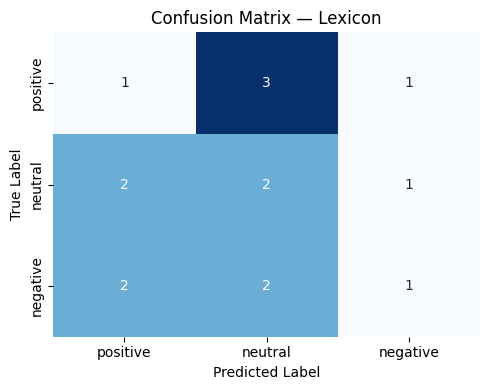

11 misclassified

true neutral  → pred positive | 친구가 인생템이라고 강추해서 따라 샀어요. 친구 피부는 진짜 좋아졌더라고요.
true neutral  → pred negative | 후기 보고 따가울까 봐 걱정돼서 팔 안쪽에 먼저 테스트해 보려고요.
true negative → pred positive | 효과는 그럭저럭 있는데 이 가격이면 굳이 재구매는 안 할 것 같아요.
true neutral  → pred positive | 주문한 다음 날 바로 왔어요!! 포장도 꼼꼼하고 사은품까지 챙겨주셔서 감동이에요ㅠㅠ
true positive → pred negative | 기대를 안 해서 그런가 생각보다 나쁘지 않네요. 자극도 없고 피지도 잘 불어서 다 쓰면 또 살 것 같아요.
true negative → pred neutral  | 배송은 하루 만에 와서 감동이었는데 제품은 실망이에요. 세 번 써봤는데 모공이 그대로예요.
true positive → pred neutral  | 이거 때문에 가지고 있던 코 팩 다 버렸어요ㅠㅠ 이제 이거 없으면 못 살 것 같아요.
true positive → pred neutral  | 처음 쓸 때 코가 살짝 따끔해서 놀랐는데 두세 번 쓰니까 적응됐어요. 블랙헤드가 눈에 띄게 줄어서 계속 쓰려고요.
true negative → pred neutral  | 피지 연화 효과 하나는 확실하네요. 코가 연화되다 못해 빨갛게 익었어요^^ 덕분에 피부과 예약했습니다.
true positive → pred neutral  | 배송이 일주일이나 걸려서 진짜 화났는데 써보니까 피지가 쏙쏙 빠져서 화가 다 풀렸어요.
true negative → pred positive | 향도 좋고 패키지도 예쁘고 사용감도 산뜻해요. 근데 정작 피지는 하나도 안 불어요. 기본이 안 되는 제품이네요.
Base prompt — Accuracy: 80.00% (3 of 15 wrong)
              precision

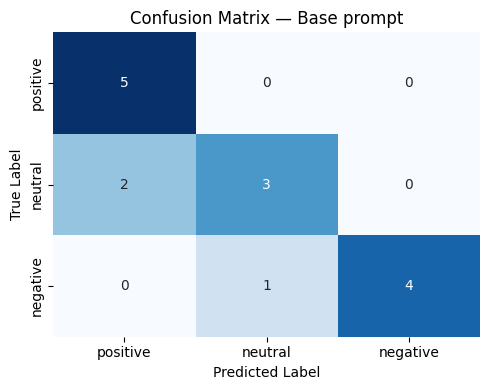

3 misclassified

true neutral  → pred positive | 친구가 인생템이라고 강추해서 따라 샀어요. 친구 피부는 진짜 좋아졌더라고요.
true negative → pred neutral  | 효과는 그럭저럭 있는데 이 가격이면 굳이 재구매는 안 할 것 같아요.
true neutral  → pred positive | 주문한 다음 날 바로 왔어요!! 포장도 꼼꼼하고 사은품까지 챙겨주셔서 감동이에요ㅠㅠ


In [ ]:
for title, col in [('Lexicon', 'lexicon_pred'),
                   ('Base prompt', 'base_pred')]:
    evaluate(df['sentiment'], df[col], title)
    show_errors(df, col)

- Lexicon 방식과 Base Prompt 방식의 예측 결과를 실제 label과 비교하여 성능 및 오분류 리뷰를 확인

# Hands-on 3

## 3-1. Improved prompt

In [ ]:
IMPROVED_PROMPT = """
Role: You are a sentiment analysis expert for Korean beauty product reviews,
familiar with Korean internet slang.

Task: Label the reviewer's overall opinion of the product itself.

Rules:
- Judge only the product. Delivery, packaging, price, discounts, events and store service are not opinions of the product.
- For mixed reviews, the reviewer's final conclusion decides.
- If the reviewer will not repurchase or recommend the product, label it negative.
- Watch for sarcasm: praise followed by a bad result (often with ^^) is negative.
- Label it neutral if there is no opinion of the product itself: not used yet, only other people's opinions,
or pros and cons listed without a conclusion.

Examples:
이 토너 진짜 미쳤네요. 바르자마자 피부결이 달라져요. -> positive
가성비 좋다길래 샀는데 그냥 물이에요. 돈 아까워요. -> negative
택배가 문 앞에 잘 도착했어요. 아직 써보진 않았어요. -> neutral

Review: {review}

Output ONLY one word: positive, negative, or neutral
"""

df['improved_pred'] = df['review_text'].apply(
    llm_predict,
    prompt_template=IMPROVED_PROMPT
)

positive | 순하고 촉촉해서 너무 만족해요. 벌써 재구매했어요....
neutral  | 친구가 인생템이라고 강추해서 따라 샀어요. 친구 피부는...
neutral  | 후기 보고 따가울까 봐 걱정돼서 팔 안쪽에 먼저 테스트...
negative | 효과는 그럭저럭 있는데 이 가격이면 굳이 재구매는 안 ...
neutral  | 주문한 다음 날 바로 왔어요!! 포장도 꼼꼼하고 사은품...
positive | 기대를 안 해서 그런가 생각보다 나쁘지 않네요. 자극도...
neutral  | 피지는 잘 녹는데 향이 너무 강해요. 장단점이 확실한 ...
negative | 배송은 하루 만에 와서 감동이었는데 제품은 실망이에요....
negative | 쓰자마자 트러블이 올라와서 최악이에요. 절대 비추합니다...
positive | 이거 때문에 가지고 있던 코 팩 다 버렸어요ㅠㅠ 이제 ...
positive | 처음 쓸 때 코가 살짝 따끔해서 놀랐는데 두세 번 쓰니...
neutral  | 리뷰 쓰면 포인트 준다길래 남겨요~ 아직 뜯지도 않았어...
negative | 피지 연화 효과 하나는 확실하네요. 코가 연화되다 못해...
positive | 배송이 일주일이나 걸려서 진짜 화났는데 써보니까 피지가...
negative | 향도 좋고 패키지도 예쁘고 사용감도 산뜻해요. 근데 정...


- 역할 부여, 구체적인 분류 규칙, Few-shot 예시, 출력 형식을 결합하여 Base Prompt를 개선
- Persona assignment + Clear and specific instructions + Few-shot + Response format 네 가지가 모두 포함

## 3-2. 세 방법 비교

Lexicon — Accuracy: 26.67% (11 of 15 wrong)
              precision    recall  f1-score   support

    positive       0.20      0.20      0.20         5
     neutral       0.29      0.40      0.33         5
    negative       0.33      0.20      0.25         5

    accuracy                           0.27        15
   macro avg       0.27      0.27      0.26        15
weighted avg       0.27      0.27      0.26        15



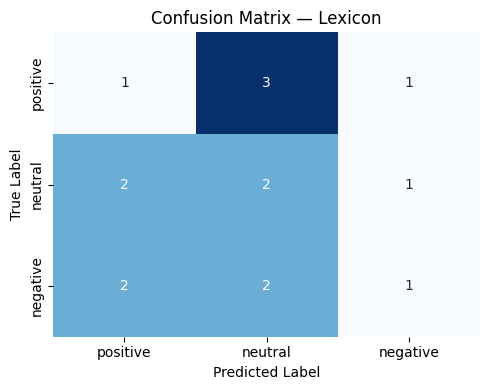

11 misclassified

true neutral  → pred positive | 친구가 인생템이라고 강추해서 따라 샀어요. 친구 피부는 진짜 좋아졌더라고요.
true neutral  → pred negative | 후기 보고 따가울까 봐 걱정돼서 팔 안쪽에 먼저 테스트해 보려고요.
true negative → pred positive | 효과는 그럭저럭 있는데 이 가격이면 굳이 재구매는 안 할 것 같아요.
true neutral  → pred positive | 주문한 다음 날 바로 왔어요!! 포장도 꼼꼼하고 사은품까지 챙겨주셔서 감동이에요ㅠㅠ
true positive → pred negative | 기대를 안 해서 그런가 생각보다 나쁘지 않네요. 자극도 없고 피지도 잘 불어서 다 쓰면 또 살 것 같아요.
true negative → pred neutral  | 배송은 하루 만에 와서 감동이었는데 제품은 실망이에요. 세 번 써봤는데 모공이 그대로예요.
true positive → pred neutral  | 이거 때문에 가지고 있던 코 팩 다 버렸어요ㅠㅠ 이제 이거 없으면 못 살 것 같아요.
true positive → pred neutral  | 처음 쓸 때 코가 살짝 따끔해서 놀랐는데 두세 번 쓰니까 적응됐어요. 블랙헤드가 눈에 띄게 줄어서 계속 쓰려고요.
true negative → pred neutral  | 피지 연화 효과 하나는 확실하네요. 코가 연화되다 못해 빨갛게 익었어요^^ 덕분에 피부과 예약했습니다.
true positive → pred neutral  | 배송이 일주일이나 걸려서 진짜 화났는데 써보니까 피지가 쏙쏙 빠져서 화가 다 풀렸어요.
true negative → pred positive | 향도 좋고 패키지도 예쁘고 사용감도 산뜻해요. 근데 정작 피지는 하나도 안 불어요. 기본이 안 되는 제품이네요.
Base prompt — Accuracy: 80.00% (3 of 15 wrong)
              precision

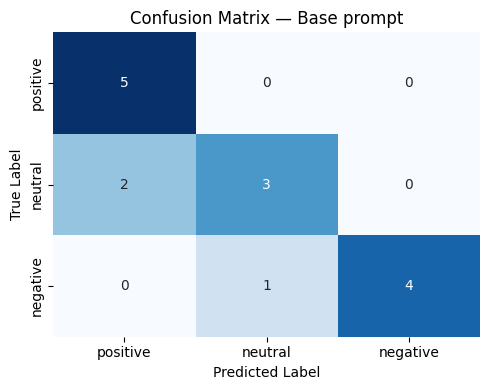

3 misclassified

true neutral  → pred positive | 친구가 인생템이라고 강추해서 따라 샀어요. 친구 피부는 진짜 좋아졌더라고요.
true negative → pred neutral  | 효과는 그럭저럭 있는데 이 가격이면 굳이 재구매는 안 할 것 같아요.
true neutral  → pred positive | 주문한 다음 날 바로 왔어요!! 포장도 꼼꼼하고 사은품까지 챙겨주셔서 감동이에요ㅠㅠ
Improved prompt — Accuracy: 100.00% (0 of 15 wrong)
              precision    recall  f1-score   support

    positive       1.00      1.00      1.00         5
     neutral       1.00      1.00      1.00         5
    negative       1.00      1.00      1.00         5

    accuracy                           1.00        15
   macro avg       1.00      1.00      1.00        15
weighted avg       1.00      1.00      1.00        15



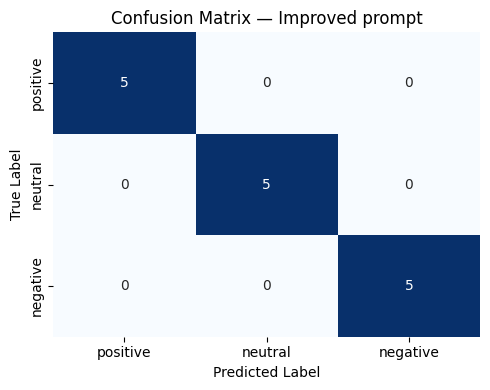

0 misclassified



In [ ]:
for title, col in [('Lexicon', 'lexicon_pred'),
                   ('Base prompt', 'base_pred'),
                   ('Improved prompt', 'improved_pred')]:
    evaluate(df['sentiment'], df[col], title)
    show_errors(df, col)

- Lexicon, Base Prompt, Improved Prompt의 감성분석 성능과 오분류 결과를 비교

## 3-3. 개선된 리뷰와 새롭게 틀린 리뷰 확인

In [ ]:
fixed = df[
    (df['sentiment'] != df['base_pred']) &
    (df['sentiment'] == df['improved_pred'])
]

broken = df[
    (df['sentiment'] == df['base_pred']) &
    (df['sentiment'] != df['improved_pred'])
]

print(f"Fixed by the improved prompt: {len(fixed)}")

for _, r in fixed.iterrows():
    print(
        f" [{r['sentiment']}] base {r['base_pred']} → "
        f"improved {r['improved_pred']} | {r['review_text'][:40]}"
    )

print(f"\nNewly wrong with the improved prompt: {len(broken)}")

for _, r in broken.iterrows():
    print(
        f" [{r['sentiment']}] base {r['base_pred']} → "
        f"improved {r['improved_pred']} | {r['review_text'][:40]}"
    )

Fixed by the improved prompt: 3
 [neutral] base positive → improved neutral | 친구가 인생템이라고 강추해서 따라 샀어요. 친구 피부는 진짜 좋아졌더라고
 [negative] base neutral → improved negative | 효과는 그럭저럭 있는데 이 가격이면 굳이 재구매는 안 할 것 같아요.
 [neutral] base positive → improved neutral | 주문한 다음 날 바로 왔어요!! 포장도 꼼꼼하고 사은품까지 챙겨주셔서 감

Newly wrong with the improved prompt: 0


- Improved Prompt를 통해 새롭게 정답으로 수정된 리뷰와 반대로 새롭게 오분류된 리뷰를 확인

> 리뷰 데이터 불러오기 → Lexicon 기반 감성분석 → Gemini Base Prompt 기반 감성분석 → 성능 평가 → 오분류 분석 → Prompt Engineering을 통한 프롬프트 개선 → 성능 재평가의 과정으로 진행